# Customer Segmentation Analysis

## Objective
Apply K-Means clustering to segment an e-commerce customer base into distinct groups based on purchasing and engagement behaviour.

### Dataset
This analysis uses the uploaded **e-commerce customer data** dataset.

### Tech Stack
Python, pandas, NumPy, scikit-learn, matplotlib, seaborn, Jupyter Notebook

## 1. Import Libraries

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")

## 2. Load the Dataset

In [5]:
df = pd.read_csv("e-commerce customer data.csv")
df.head()

,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\nCobbborough, D...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\nPort Jason, OH 22070-1220",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\nPort Jacobville, PR 3...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


## 3. Inspect the Dataset

In [6]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Shape: (500, 8)

Columns:
['Email', 'Address', 'Avatar', 'Avg. Session Length', 'Time on App', 'Time on Website', 'Length of Membership', 'Yearly Amount Spent']

Data Types:
Email                       str
Address                     str
Avatar                      str
Avg. Session Length     float64
Time on App             float64
Time on Website         float64
Length of Membership    float64
Yearly Amount Spent     float64
dtype: object

Missing Values:
Email                   0
Address                 0
Avatar                  0
Avg. Session Length     0
Time on App             0
Time on Website         0
Length of Membership    0
Yearly Amount Spent     0
dtype: int64

Duplicate Rows: 0


### Data Quality Observation

The dataset contains 500 customer records and 8 columns. There are no missing values and no duplicate rows. The dataset contains customer contact/profile fields as well as numerical engagement and spending variables.

For clustering, we will use behavioural variables rather than Email, Address, or Avatar.

## 4. Descriptive Statistics

In [7]:
numeric_cols = [
    "Avg. Session Length",
    "Time on App",
    "Time on Website",
    "Length of Membership",
    "Yearly Amount Spent"
]

df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Avg. Session Length,500.0,33.053194,0.992563,29.532429,32.341822,33.082008,33.711985,36.139662
Time on App,500.0,12.052488,0.994216,8.508152,11.388153,11.983231,12.753850,15.126994
Time on Website,500.0,37.060445,1.010489,33.913847,36.349257,37.069367,37.716432,40.005182
Length of Membership,500.0,3.533462,0.999278,0.269901,2.930450,3.533975,4.126502,6.922689
Yearly Amount Spent,500.0,499.314038,79.314782,256.670582,445.038277,498.887875,549.313828,765.518462


### Interpretation

The descriptive statistics show the central tendency and variation of customer engagement and spending.

- **Avg. Session Length** measures average session duration.
- **Time on App** and **Time on Website** measure engagement with each channel.
- **Length of Membership** represents customer tenure.
- **Yearly Amount Spent** is the available customer-value measure.

Because this dataset does not contain transaction dates or transaction-level purchase history, a traditional RFM analysis and true lifetime-value calculation cannot be performed. Yearly Amount Spent is therefore used as a customer-value indicator.

## 5. Feature Selection

We will use three behavioural features for clustering:

1. **Avg. Session Length**
2. **Time on App**
3. **Length of Membership**

These features represent engagement and customer tenure. **Yearly Amount Spent** is kept out of the clustering input so that it can be used to profile the resulting customer segments.

In [8]:
cluster_features = [
    "Avg. Session Length",
    "Time on App",
    "Length of Membership"
]

X = df[cluster_features].copy()
X.head()

,Avg. Session Length,Time on App,Length of Membership
0,34.497268,12.655651,4.082621
1,31.926272,11.109461,2.664034
2,33.000915,11.330278,4.104543
3,34.305557,13.717514,3.120179
4,33.330673,12.795189,4.446308


## 6. Standardise the Features

K-Means uses distance calculations. Standardisation prevents a feature with a larger numerical scale from dominating the clustering process.

In [9]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=cluster_features
)

X_scaled.head()

,Avg. Session Length,Time on App,Length of Membership
0,1.456351,0.607280,0.550107
1,-1.136502,-0.949464,-0.870927
2,-0.052723,-0.727139,0.572067
3,1.263010,1.676390,-0.413996
4,0.279838,0.747770,0.914422


## 7. Elbow Method

The Elbow Method compares the within-cluster sum of squares (inertia) for different values of K. We look for a point where increasing K produces progressively smaller improvements.

In [10]:
inertia = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    inertia.append(model.inertia_)

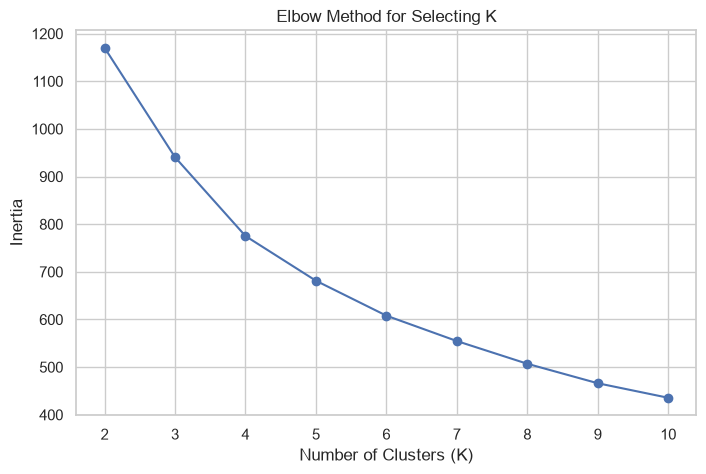

In [11]:
plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Selecting K")
plt.xticks(range(2, 11))
plt.show()

### Elbow Observation

The inertia decreases as the number of clusters increases. The curve does not have an extremely sharp elbow, so K should be selected with practical interpretability in mind. For this project, **K = 4** is used to create four interpretable customer segments while avoiding an unnecessarily large number of groups.

The choice is therefore an analytical modelling choice rather than a claim that the dataset has one uniquely correct K.

## 8. Apply K-Means Clustering

In [12]:
k = 4

kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

df[["Email", "Cluster"]].head()

,Email,Cluster
0,mstephenson@fernandez.com,2
1,hduke@hotmail.com,1
2,pallen@yahoo.com,3
3,riverarebecca@gmail.com,0
4,mstephens@davidson-herman.com,2


## 9. Cluster Validation

Silhouette score provides an additional diagnostic of how separated the clusters are. It is used here as supporting information rather than as the sole decision rule.

In [13]:
silhouette = silhouette_score(X_scaled, df["Cluster"])

print("Silhouette Score:", round(silhouette, 4))

Silhouette Score: 0.2295


## 10. Visualise the Customer Clusters

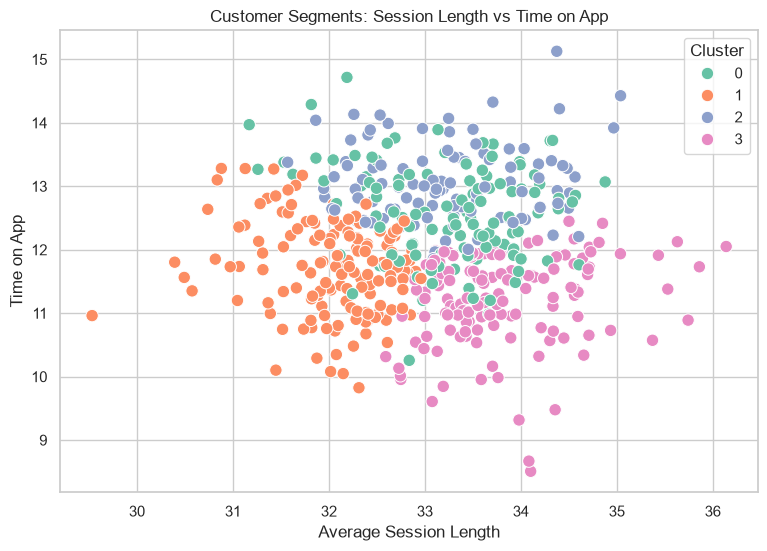

In [14]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Avg. Session Length",
    y="Time on App",
    hue="Cluster",
    palette="Set2",
    s=80
)

plt.title("Customer Segments: Session Length vs Time on App")
plt.xlabel("Average Session Length")
plt.ylabel("Time on App")
plt.legend(title="Cluster")
plt.show()

### Observation

The scatter plot shows how customers are separated using average session length and app engagement. The clusters should be interpreted together with their numerical profiles because some groups may overlap in two-dimensional space.

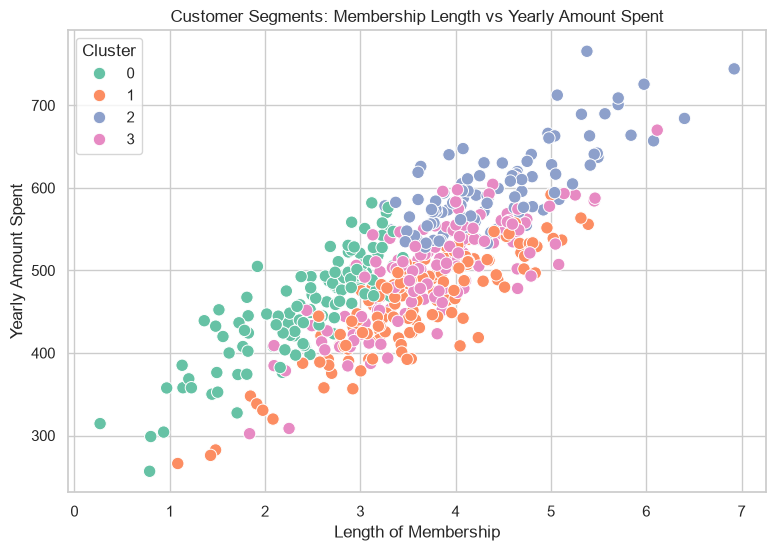

In [15]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Length of Membership",
    y="Yearly Amount Spent",
    hue="Cluster",
    palette="Set2",
    s=80
)

plt.title("Customer Segments: Membership Length vs Yearly Amount Spent")
plt.xlabel("Length of Membership")
plt.ylabel("Yearly Amount Spent")
plt.legend(title="Cluster")
plt.show()

### Observation

This plot compares customer tenure with yearly spending. It helps show whether the segments differ in customer value even though spending was not used as an input feature for K-Means.

## 11. Cluster Profiling

In [16]:
cluster_profile = df.groupby("Cluster").agg(
    Customer_Count=("Cluster", "size"),
    Avg_Session_Length=("Avg. Session Length", "mean"),
    Avg_Time_on_App=("Time on App", "mean"),
    Avg_Time_on_Website=("Time on Website", "mean"),
    Avg_Membership_Length=("Length of Membership", "mean"),
    Avg_Yearly_Spend=("Yearly Amount Spent", "mean")
).round(2)

cluster_profile

,Customer_Count,Avg_Session_Length,Avg_Time_on_App,Avg_Time_on_Website,Avg_Membership_Length,Avg_Yearly_Spend
Cluster,,,,,,
0,120,33.23,12.56,37.12,2.45,457.58
1,143,32.02,11.71,37.06,3.57,461.29
2,103,33.25,13.04,37.08,4.42,596.92
3,134,33.84,11.21,36.99,3.78,502.24


### Segment Interpretation

Use the profile table above to interpret the clusters:

- A cluster with higher engagement and higher yearly spending can be treated as a **high-value engaged segment**.
- A cluster with lower engagement and lower spending can be treated as a **low-engagement segment**.
- A cluster with stronger membership tenure can be treated as a **longer-tenure customer segment**.
- A cluster with stronger app engagement can be treated as an **app-focused segment**.

The labels should be based on the actual profile values rather than assuming that a particular cluster number always represents the same customer type.

## 12. Number of Customers per Cluster

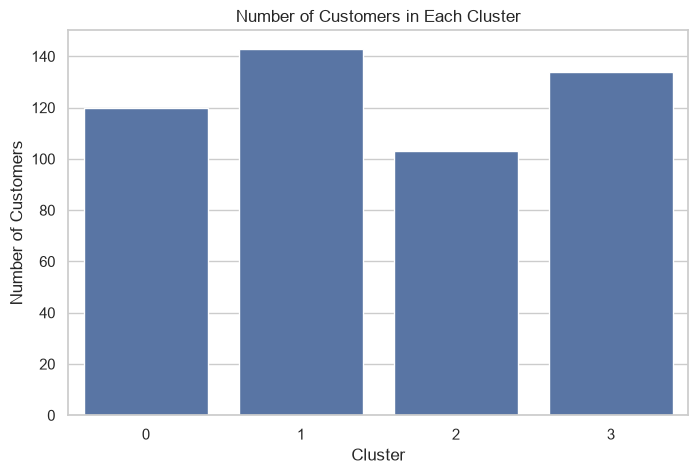

In [17]:
cluster_counts = df["Cluster"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
sns.barplot(
    x=cluster_counts.index,
    y=cluster_counts.values
)

plt.title("Number of Customers in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.show()

### Observation

The bar chart shows the size of each customer segment. Segment size is important for campaign planning because a large segment may require scalable communication, while a smaller high-value segment may justify more personalised marketing.

## 13. Additional Insight: App vs Website Engagement

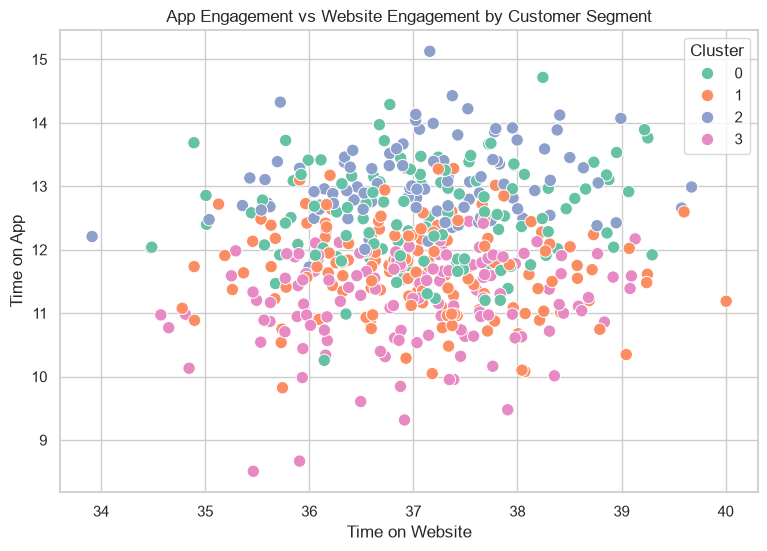

In [18]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Time on Website",
    y="Time on App",
    hue="Cluster",
    palette="Set2",
    s=80
)

plt.title("App Engagement vs Website Engagement by Customer Segment")
plt.xlabel("Time on Website")
plt.ylabel("Time on App")
plt.legend(title="Cluster")
plt.show()

### Additional Insight

Comparing app and website engagement can reveal whether customer segments differ in their preferred digital channel. This can support channel-specific campaigns, such as app notifications for app-focused customers or website-based promotions for customers with stronger website engagement.

## 14. Marketing Recommendations

### High-Value / Highly Engaged Customers
- Provide loyalty rewards and exclusive benefits.
- Offer early access to new products.
- Use personalised recommendations and premium offers.

### Low-Engagement Customers
- Run re-engagement email or notification campaigns.
- Offer limited-time incentives to encourage another visit.
- Test simpler and more relevant product recommendations.

### Long-Tenure Customers
- Build loyalty programmes around membership duration.
- Offer anniversary rewards or retention benefits.
- Encourage referrals and repeat purchases.

### App-Focused Customers
- Use app notifications and personalised in-app offers.
- Promote app-only discounts or loyalty benefits.
- Optimise the mobile shopping journey for this segment.

**Note:** The exact label assigned to each Cluster number should be matched to the `cluster_profile` table after the notebook is run.

# 15. Conclusion

K-Means clustering was used to segment 500 e-commerce customers according to engagement and membership behaviour. The analysis standardised three behavioural features — average session length, time on app, and length of membership — and used the Elbow Method to select four clusters.

The resulting segments can support targeted marketing rather than treating all customers identically. The cluster profiles also show how engagement patterns relate to yearly customer spending, which can help prioritise retention, loyalty, re-engagement, and channel-specific campaigns.

### Key Business Actions
1. Personalise offers for highly engaged and high-spending customers.
2. Use targeted re-engagement campaigns for low-engagement customers.
3. Strengthen loyalty and retention programmes for longer-tenure customers.
4. Tailor campaigns to customers' preferred app or website engagement channel.

### Dataset Limitation
This dataset does not contain transaction dates, transaction frequency, or individual transaction records. Therefore, traditional RFM analysis and a true customer lifetime-value calculation are not supported by the available data. Yearly Amount Spent is used as a customer-value indicator instead.